In [1]:
# -----------------------------------------------------------------------
# 0. Libraries and Reproducibility setup
# -----------------------------------------------------------------------
import sys
import os
import warnings
import numpy as np
import matplotlib
import scipy
import sklearn
from scipy import stats
import matplotlib.pyplot as plt
from sklearn.gaussian_process import GaussianProcessRegressor
from sklearn.gaussian_process.kernels import (Matern, ConstantKernel, WhiteKernel)
from scipy.stats import norm, qmc
from scipy.optimize import minimize
from sklearn.model_selection import LeaveOneOut
from sklearn.exceptions import ConvergenceWarning
warnings.filterwarnings("ignore", category=ConvergenceWarning)

SEED = 42
rng = np.random.default_rng(SEED)
np.random.seed(SEED)
SK_RANDOM_STATE = np.random.RandomState(SEED)  # sklearn wants a RandomState

print("=" * 100)
print("Software and Libraries used")
print("=" * 100)
print(f"  python      : {sys.version.split()[0]}")
print(f"  numpy       : {np.__version__}")
print(f"  scipy       : {scipy.__version__}")
print(f"  scikit-learn: {sklearn.__version__}")
print(f"  matplotlib  : {matplotlib.__version__}")
print(f"  SEED        : {SEED}")
print()

# ---------------------------------------------------------------- 
# Figures settings
# ---------------------------------------------------------------- 
SURFACE, INK, INK2, MUTED, GRIDC = "#fcfcfb", "#0b0b0b", "#52514e", "#898781", "#e6e5e1"
BLUE, ORANGE, AQUA, MAGENTA = "#2a78d6", "#eb6834", "#1baf7a", "#e87ba4"
plt.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
    "font.size": 10, "text.color": INK, "axes.edgecolor": MUTED, "axes.labelcolor": INK2,
    "xtick.color": MUTED, "ytick.color": MUTED, "xtick.labelcolor": INK2, "ytick.labelcolor": INK2,
    "axes.spines.top": False, "axes.spines.right": False, "axes.grid": True,
    "grid.color": GRIDC, "grid.linewidth": 0.8, "axes.axisbelow": True,
    "axes.titlesize": 11, "axes.titleweight": "bold", "axes.titlelocation": "left",
})

Software and Libraries used
  python      : 3.13.9
  numpy       : 2.3.5
  scipy       : 1.16.3
  scikit-learn: 1.9.0
  matplotlib  : 3.11.1
  SEED        : 42



In [2]:
# ---------------------------------------------------------------------------
# 1. DATA
# ---------------------------------------------------------------------------
X = np.load('..\Function_6_Data\Week_10_Data/F6_Week_10_inputs.npy')
y = np.load('..\Function_6_Data\Week_10_Data/F6_Week_10_outputs.npy')
n, d = X.shape
DIM_NAMES = [f"x{i+1}" for i in range(d)]
BOUNDS = [(0.0, 1.0)] * d
N_ORIGINAL = 20  

print("=" * 100)
print("DATA: INITIAL DESIGN VS QUERIED POINTS")
print("=" * 100)
print(f"n_samples: {N_ORIGINAL} initial + {n - N_ORIGINAL} queried = {n}")

running = y[:N_ORIGINAL].max()

prev_best = y[:N_ORIGINAL].max()
new_best = y.max()
print(f"\nBest of initial design  : {prev_best:.5f}  (idx {y[:N_ORIGINAL].argmax()})")
print(f"Current incumbent best  : {new_best:.5f}  (idx {y.argmax()})")
print(f"Improvement             : {new_best - prev_best:+.5f}")

DATA: INITIAL DESIGN VS QUERIED POINTS
n_samples: 20 initial + 9 queried = 29

Best of initial design  : -0.71426  (idx 0)
Current incumbent best  : -0.40482  (idx 27)
Improvement             : +0.30944


DATA TRANSFORMATION
Output range: [-2.5712, -0.4048]
Standardising y (z-score) on the FULL updated dataset -> refit mean/std.




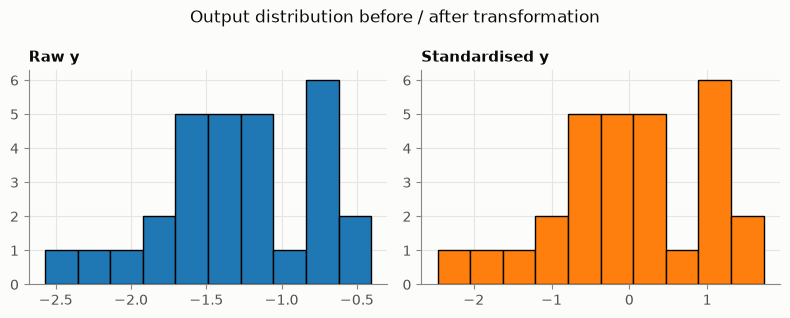

In [3]:
# ---------------------------------------------------------------------------
# DATA TRANSFORMATION
# ---------------------------------------------------------------------------
print("=" * 100)
print("DATA TRANSFORMATION")
print("=" * 100)

print(f"Output range: [{y.min():.4f}, {y.max():.4f}]")
print("Standardising y (z-score) on the FULL updated dataset -> refit mean/std.")

y_mean, y_std = y.mean(), y.std()
y_z = (y - y_mean) / y_std
# 

print('\n')
fig, axes = plt.subplots(1, 2, figsize=(8, 3.2))
axes[0].hist(y, bins=10, color="#1f77b4", edgecolor="k")
axes[0].set_title("Raw y")
axes[1].hist(y_z, bins=10, color="#ff7f0e", edgecolor="k")
axes[1].set_title("Standardised y")
fig.suptitle("Output distribution before / after transformation")
fig.tight_layout()

SURROGATE MODEL SELECTION
LOO total log predictive density - isotropic :  -36.094
LOO total log predictive density - ARD       :  -47.809
-> isotropic has the higher LOO log predictive density at n=29.

Final kernel (fitted hyper-parameters, n=29):
  1.25**2 * Matern(length_scale=0.773, nu=2.5) + WhiteKernel(noise_level=0.000269)

Diagnostic ARD length-scales (interpretation only):
  x1: length_scale = 0.881
  x2: length_scale = 0.697
  x3: length_scale = 0.985
  x4: length_scale = 1.094
  x5: length_scale = 2.062




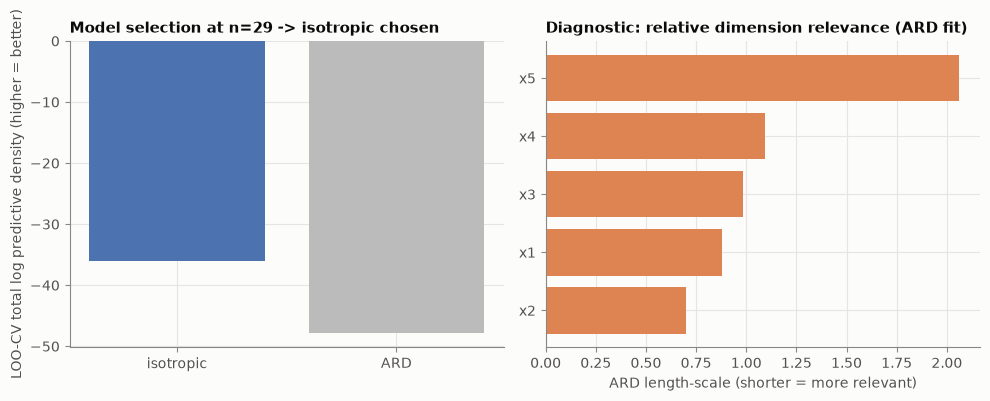

In [4]:
# ---------------------------------------------------------------------------
# SURROGATE MODEL: re-run ARD vs isotropic model selection
# ---------------------------------------------------------------------------
print("=" * 100)
print(f"SURROGATE MODEL SELECTION")
print("=" * 100)

def make_kernel(ard: bool):
    length_scale = np.ones(d) if ard else 1.0
    return (
        ConstantKernel(1.0, (1e-2, 1e2))
        * Matern(length_scale=length_scale, length_scale_bounds=(1e-2, 1e1), nu=2.5)
        + WhiteKernel(noise_level=1e-2, noise_level_bounds=(1e-5, 1e0))
    )

def fit_gp(X_train, y_train, ard: bool, n_restarts=20):
    gp = GaussianProcessRegressor(
        kernel=make_kernel(ard),
        n_restarts_optimizer=n_restarts,
        normalize_y=False,
        alpha=1e-10,
        random_state=SEED,
    )
    gp.fit(X_train, y_train)
    return gp

def loo_log_predictive_density(X, y, ard: bool):
    total = 0.0
    for i in range(len(y)):
        X_tr, y_tr = np.delete(X, i, axis=0), np.delete(y, i)
        gp = fit_gp(X_tr, y_tr, ard=ard, n_restarts=5)
        mu, sigma = gp.predict(X[i:i + 1], return_std=True)
        sigma = max(sigma[0], 1e-6)
        total += norm.logpdf(y[i], loc=mu[0], scale=sigma)
    return total

loo_iso = loo_log_predictive_density(X, y_z, ard=False)
loo_ard = loo_log_predictive_density(X, y_z, ard=True)
print(f"LOO total log predictive density - isotropic : {loo_iso:8.3f}")
print(f"LOO total log predictive density - ARD       : {loo_ard:8.3f}")
use_ard = loo_ard > loo_iso
winner = "ARD" if use_ard else "isotropic"
print(f"-> {winner} has the higher LOO log predictive density at n={n}.")

gp_final = fit_gp(X, y_z, ard=use_ard, n_restarts=30)
print(f"\nFinal kernel (fitted hyper-parameters, n={n}):")
print(" ", gp_final.kernel_)

# diagnostic ARD fit for interpretation
gp_ard_diag = fit_gp(X, y_z, ard=True, n_restarts=30)
length_scales = gp_ard_diag.kernel_.k1.k2.length_scale
print("\nDiagnostic ARD length-scales (interpretation only):")
for name, ls in zip(DIM_NAMES, length_scales):
    print(f"  {name}: length_scale = {ls:.3f}")

print('\n')

fig, axes = plt.subplots(1, 2, figsize=(10, 4))
axes[0].bar(["isotropic", "ARD"], [loo_iso, loo_ard],
            color=["#4c72b0" if not use_ard else "#bbbbbb",
                   "#4c72b0" if use_ard else "#bbbbbb"])
axes[0].set_ylabel("LOO-CV total log predictive density (higher = better)")
axes[0].set_title(f"Model selection at n={n} -> {winner} chosen")
order = np.argsort(length_scales)
axes[1].barh([DIM_NAMES[k] for k in order], length_scales[order], color="#dd8452")
axes[1].set_xlabel("ARD length-scale (shorter = more relevant)")
axes[1].set_title("Diagnostic: relative dimension relevance (ARD fit)")
fig.tight_layout()

In [5]:
# ---------------------------------------------------------------------------
# ACQUISITION - Propose next point
# ---------------------------------------------------------------------------
print("=" * 100)
print("ACQUISITION: Next query point")
print("=" * 100)

f_best_z = y_z.max()
XI = 0.01
KAPPA = 2.0

print(f"xi is kept at {XI} (standardised y units).")

def expected_improvement(Xq, gp, f_best, xi=XI):
    Xq = np.atleast_2d(Xq)
    mu, sigma = gp.predict(Xq, return_std=True)
    sigma = np.maximum(sigma, 1e-9)
    z = (mu - f_best - xi) / sigma
    return (mu - f_best - xi) * norm.cdf(z) + sigma * norm.pdf(z)

def upper_confidence_bound(Xq, gp, kappa=KAPPA):
    Xq = np.atleast_2d(Xq)
    mu, sigma = gp.predict(Xq, return_std=True)
    return mu + kappa * sigma

def optimise_acquisition(neg_acq_fn, bounds, n_restarts=24, n_sobol=2**13, seed=SEED):
    # REV R3: score a Sobol sample plus the observed points, then polish the
    # best n_restarts of them. Own seed per call, so the result does not
    # depend on what was optimised before.
    dim = len(bounds)
    lo = np.array([b[0] for b in bounds]); hi = np.array([b[1] for b in bounds])
    cands = np.vstack([lo + qmc.Sobol(dim, seed=seed).random(n_sobol) * (hi - lo), X])
    scores = np.array([neg_acq_fn(c) for c in cands])
    starts = cands[np.argsort(scores)[:n_restarts]]
    best_x, best_val = None, -np.inf
    for x0 in starts:
        res = minimize(neg_acq_fn, x0=x0, method="L-BFGS-B", bounds=bounds)
        val = -float(res.fun)
        if val > best_val:
            best_val, best_x = val, res.x
    return np.clip(best_x, 0.0, 1.0), best_val

x_next_ei, ei_val = optimise_acquisition(
    lambda x: -expected_improvement(x.reshape(1, -1), gp_final, f_best_z)[0], BOUNDS)
x_next_ucb, ucb_val = optimise_acquisition(
    lambda x: -upper_confidence_bound(x.reshape(1, -1), gp_final, KAPPA)[0], BOUNDS)

mu_z, sig_z = gp_final.predict(x_next_ei.reshape(1, -1), return_std=True)
mu_raw = mu_z[0] * y_std + y_mean
sig_raw = sig_z[0] * y_std

print(f"Current incumbent best (raw y): {new_best:.6f} at x={X[y.argmax()].round(4)}")
print(f"\n[Next point via EI]")
print(f"  x_next = {x_next_ei.round(6)}")
print(f"  GP predicted y: {mu_raw:.6f} +/- {2*sig_raw:.6f} (95% band)")
print(f"[Cross-check UCB point]: {x_next_ucb.round(6)}  "
      f"(distance from EI point: {np.linalg.norm(x_next_ei - x_next_ucb):.6f})")


ACQUISITION: Next query point
xi is kept at 0.01 (standardised y units).
Current incumbent best (raw y): -0.404822 at x=[0.4342 0.454  0.4175 0.7306 0.1258]

[Next point via EI]
  x_next = [0.472358 0.451118 0.460178 0.628744 0.078485]
  GP predicted y: -0.430707 +/- 0.147183 (95% band)
[Cross-check UCB point]: [0.459877 0.491621 0.536246 0.590151 0.      ]  (distance from EI point: 0.123418)


PLOTS


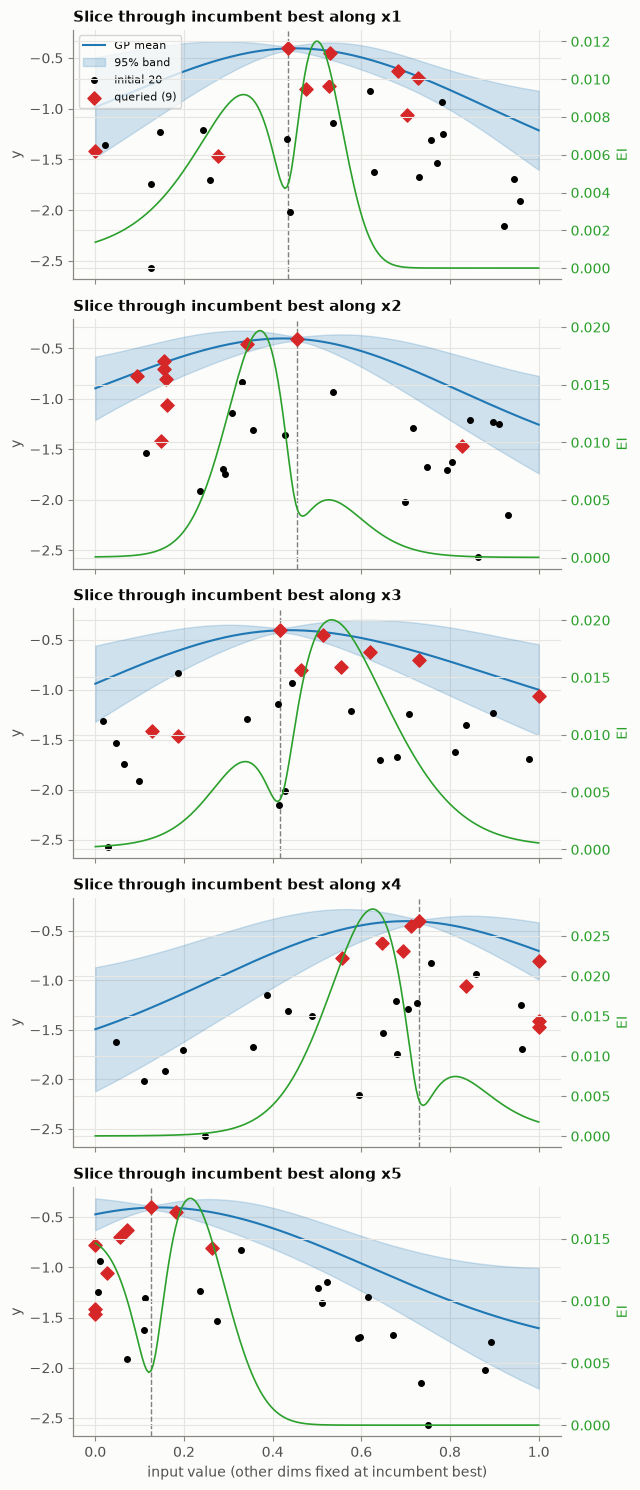

In [6]:
# ---------------------------------------------------------------------------
# 5. PLOTS
# ---------------------------------------------------------------------------
print("=" * 100)
print("PLOTS")
print("=" * 100)

x_star = X[y.argmax()].copy()
grid = np.linspace(0, 1, 200)

fig, axes = plt.subplots(d, 1, figsize=(6.5, 3 * d), sharex=True)
for k in range(d):
    Xg = np.tile(x_star, (len(grid), 1))
    Xg[:, k] = grid
    mu_z, sig_z = gp_final.predict(Xg, return_std=True)
    mu_r = mu_z * y_std + y_mean
    sig_r = sig_z * y_std
    ei_curve = expected_improvement(Xg, gp_final, f_best_z)

    ax = axes[k]
    ax.plot(grid, mu_r, color="#1f77b4", label="GP mean")
    ax.fill_between(grid, mu_r - 2 * sig_r, mu_r + 2 * sig_r,
                     color="#1f77b4", alpha=0.2, label="95% band")
    ax.scatter(X[:N_ORIGINAL, k], y[:N_ORIGINAL], color="k", s=16, zorder=5,
               label=f"initial {N_ORIGINAL}")
    ax.scatter(X[N_ORIGINAL:, k], y[N_ORIGINAL:], color="#d62728", s=45,
               marker="D", zorder=6, label=f"queried ({n - N_ORIGINAL})")
    ax.axvline(x_star[k], color="gray", ls="--", lw=1)

    ax2 = ax.twinx()
    ax2.plot(grid, ei_curve, color="#2ca02c", lw=1.2)
    ax2.set_ylabel("EI", color="#2ca02c")
    ax2.tick_params(axis="y", labelcolor="#2ca02c")

    ax.set_ylabel("y")
    ax.set_title(f"Slice through incumbent best along {DIM_NAMES[k]}")
    if k == 0:
        ax.legend(loc="upper left", fontsize=8)

axes[-1].set_xlabel("input value (other dims fixed at incumbent best)")
fig.tight_layout()

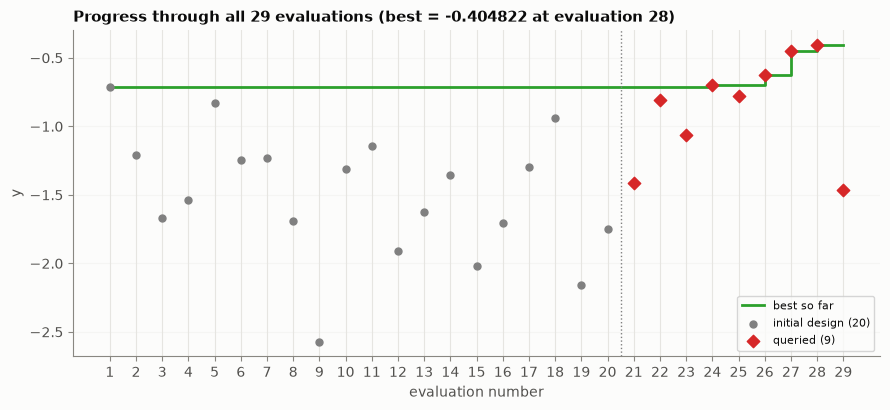

In [7]:
best_so_far = np.maximum.accumulate(np.r_[np.full(N_ORIGINAL, y[:N_ORIGINAL].max()), y[N_ORIGINAL:]])
fig, ax = plt.subplots(figsize=(9, 4.2))
ax.step(range(1, n + 1), best_so_far, where="post", color="#2ca02c", lw=2, label="best so far")
ax.scatter(range(1, N_ORIGINAL + 1), y[:N_ORIGINAL], color="gray", s=25,
           zorder=3, label=f"initial design ({N_ORIGINAL})")
ax.scatter(range(N_ORIGINAL + 1, n + 1), y[N_ORIGINAL:], color="#d62728", s=40,
           marker="D", zorder=3, label=f"queried ({n - N_ORIGINAL})")
ax.axvline(N_ORIGINAL + 0.5, color="gray", ls=":", lw=1)
ax.set_xticks(range(1, n + 1))
ax.set_xlabel("evaluation number")
ax.set_ylabel("y")
ax.set_title(f"Progress through all {n} evaluations (best = {y.max():.6f} at evaluation {y.argmax() + 1})")
ax.grid(axis="y", alpha=0.3)
ax.legend(fontsize=8, loc="lower right")
fig.tight_layout()

In [8]:
print("\nRECOMMENDED NEXT SINGLE QUERY POINT (sequential EI):")
print("  x_next =", np.round(x_next_ei, 6).tolist())


RECOMMENDED NEXT SINGLE QUERY POINT (sequential EI):
  x_next = [0.472358, 0.451118, 0.460178, 0.628744, 0.078485]
